In [2]:
import os
from pathlib import Path
from typing import Literal, Optional, List

import numpy as np
import math
import uproot as uproot
import pickle
import pandas as pd
import awkward as ak
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white"})
import matplotlib.colors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
from matplotlib import gridspec
import seaborn as sns
from matplotlib.ticker import MaxNLocator

# My imports
#from src.utils import *

In [3]:
fransDir = Path("/exp/sbnd/data/users/syebes/eafData/fransOutputs")
lambdaFile = "lambdaFransOutput.root"
fransTDir = "FRANSProducer/fransTree"

In [4]:
file = uproot.open(fransDir / lambdaFile)

fransTree = file[fransTDir]

In [5]:
file.keys()

['FRANSProducer;1',
 'FRANSProducer/fransTree;1',
 'FRANSProducer/subrunTree;1',
 'lambdaPidPandoraAna;1',
 'lambdaPidPandoraAna/hDecayInvariantMass;1',
 'lambdaPidPandoraAna/CalorimetryTree;1',
 'myAnalyzer;1',
 'myAnalyzer/subrunTree;1',
 'myAnalyzer/tree;1']

In [6]:
ana_tree = file['myAnalyzer/tree']

In [7]:
fransTree.keys()

['file_name',
 'event_id',
 'run_id',
 'subrun_id',
 'slice_id',
 'gen_index',
 'nu_pdg',
 'nu_e0',
 'nu_weight',
 'nu_int_mode',
 'nu_int_type',
 'nu_cc_nc',
 'nu_target',
 'nu_hit_nuc',
 'nu_hit_quark',
 'nu_w',
 'nu_x',
 'nu_y',
 'nu_q_sqr',
 'gen_id',
 'gen_status_code',
 'gen_mother',
 'gen_pdg',
 'gen_mass',
 'gen_e0',
 'gen_start_x',
 'gen_start_y',
 'gen_start_z',
 'gen_p0_x',
 'gen_p0_y',
 'gen_p0_z',
 'n_protons',
 'n_neutrons',
 'n_pi0',
 'n_pip',
 'n_pim',
 'n_mup',
 'n_mum',
 'n_ep',
 'n_em',
 'n_lambda',
 'n_sigma0',
 'n_sigmap',
 'n_sigmam',
 'n_hyperon',
 'g4_id',
 'g4_mother',
 'g4_pdg',
 'g4_mass',
 'g4_e0',
 'g4_ef',
 'g4_tl',
 'g4_start_x',
 'g4_start_y',
 'g4_start_z',
 'g4_start_time_tick',
 'g4_start_channel_u',
 'g4_start_channel_v',
 'g4_start_channel_c',
 'g4_end_x',
 'g4_end_y',
 'g4_end_z',
 'g4_end_time_tick',
 'g4_end_channel_u',
 'g4_end_channel_v',
 'g4_end_channel_c',
 'g4_p0_x',
 'g4_p0_y',
 'g4_p0_z',
 'g4_pf_x',
 'g4_pf_y',
 'g4_pf_z',
 'g4_process',

In [8]:
branches = [
    'file_name',
    'event_id',
    'run_id',
    'subrun_id',
    'slice_id',
    'gen_index',
    'nu_pdg',
    'nu_e0',
    'nu_weight',
    'nu_int_mode',
    'nu_int_type',
    'nu_cc_nc',
    'nu_target',
    'nu_hit_nuc',
    'nu_hit_quark',
    'nu_w',
    'nu_x',
    'nu_y',
    'nu_q_sqr',
    #'gen_id',
    #'gen_status_code',
    #'gen_mother',
    #'gen_pdg',
    #'gen_mass',
    #'gen_e0',
    #'gen_start_x',
    #'gen_start_y',
    #'gen_start_z',
    #'gen_p0_x',
    #'gen_p0_y',
    #'gen_p0_z',
    #'g4_id',
    #'g4_mother',
    #'g4_pdg',
    #'g4_mass',
    #'g4_e0',
    #'g4_ef',
    #'g4_tl',
    #'g4_start_x',
    #'g4_start_y',
    #'g4_start_z',
    #'g4_start_time_tick',
    #'g4_start_channel_u',
    #'g4_start_channel_v',
    #'g4_start_channel_c',
    #'g4_end_x',
    #'g4_end_y',
    #'g4_end_z',
    #'g4_end_time_tick',
    #'g4_end_channel_u',
    #'g4_end_channel_v',
    #'g4_end_channel_c',
    #'g4_p0_x',
    #'g4_p0_y',
    #'g4_p0_z',
    #'g4_pf_x',
    #'g4_pf_y',
    #'g4_pf_z',
    #'g4_process',
    #'g4_end_process',
    'n_protons',
    'n_neutrons',
    'n_pi0',
    'n_pip',
    'n_pim',
    'n_mup',
    'n_mum',
    'n_ep',
    'n_em',
    'n_lambda',
    'n_sigma0',
    'n_sigmap',
    'n_sigmam',
    'n_hyperon',
    'true_gap',
    'is_lambda_signal',
    'has_lambda',
    'has_lambda_v',
    'prim_lepton_vtx_x',
    'prim_lepton_vtx_y',
    'prim_lepton_vtx_z',
    'n_lambda', 
    'frans_score',
    'true_muon_in_fv',
    'true_muon_decay',
    'michel_vars_computed',
    'michel_n_muon_tracks',
    'michel_rss_ratio',
    'michel_angle_q80',
    'michel_drop_radius',
    'michel_n_blips',
    'michel_score',
    'frans_succeed',
]

In [9]:
michel_branches =['michel_vars_computed',
    'michel_n_muon_tracks',
    'michel_rss_ratio',
    'michel_angle_q80',
    'michel_drop_radius',
    'michel_n_blips',
    'michel_score']

In [10]:
data = {
        b: fransTree[b].array(library="np", entry_stop=None)
        for b in branches
    }
df = pd.DataFrame(data)

In [11]:
df.frans_succeed.value_counts()

frans_succeed
False    94035
True     26896
Name: count, dtype: int64

In [12]:
true_michel_mask = (df.is_lambda_signal) & (df.true_muon_in_fv) & (df.true_muon_decay) & (df.frans_succeed)

In [13]:
michel_df = df[true_michel_mask]

In [14]:
michel_df[michel_df.michel_vars_computed].michel_n_muon_tracks.value_counts()

michel_n_muon_tracks
2    3468
1    2530
3     162
4      37
5       4
Name: count, dtype: int64

<Axes: >

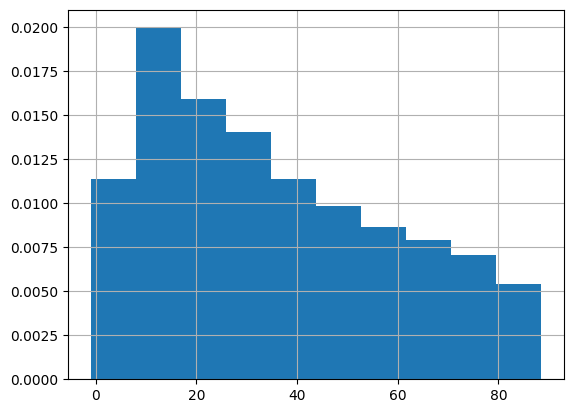

In [15]:
michel_df[michel_df.michel_vars_computed].michel_angle_q80.hist(density=True)

# 1D plots

In [16]:
COLORS = ["blue", "red", "green"]

def plot_feature(df, var, bins=40, xlabel=None, discrete=False):

    signal     = df[df['true_muon_decay'] == True]
    background = df[df['true_muon_decay'] == False]
    y = df['true_muon_decay'].astype(int)    
    
    sig_vals = signal[var].dropna()
    bkg_vals = background[var].dropna()
    
    valid = df[var].notna()
    #auc = roc_auc_score(y[valid], df.loc[valid, var])
    #auc = max(auc, 1 - auc)  # asegurar auc >= 0.5
    
    figure, ax = plt.subplots(figsize=(8, 5))

    if discrete:
        min_bins = min(bins)
        max_bins = max(bins)
        bins = np.arange(min_bins - 0.5, max_bins + 1.5)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        plt.xticks(np.arange(min_bins, max_bins + 1, 1))
    
    ax.hist(sig_vals, bins=bins, density=True,
            alpha=0.5, color=COLORS[0], label=r'$\mu$ decay')
    ax.hist(bkg_vals, bins=bins, density=True,
        alpha=0.5, color=COLORS[1],  label=r'$\mu$ captured')

    if xlabel:
        ax.set_xlabel(xlabel, fontsize=16)
    else:
        ax.set_xlabel(var, fontsize=16)
        
    ax.set_ylabel('Density', fontsize=16)
    #ax.set_title(f'AUC: {auc:.3f}', fontsize = 20)
    ax.tick_params(axis='both', labelsize=12)
    ax.legend(fontsize=12)
    ax.grid(False)
    plt.tight_layout()
    plt.show()

/cvmfs/larsoft.opensciencegrid.org/spack-fnal-v1.0.0/opt/spack/linux-x86_64_v2/py-numpy-1.26.4-bjfwdigla2ihyygih63foelrl4jedvx2/lib/python3.10/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


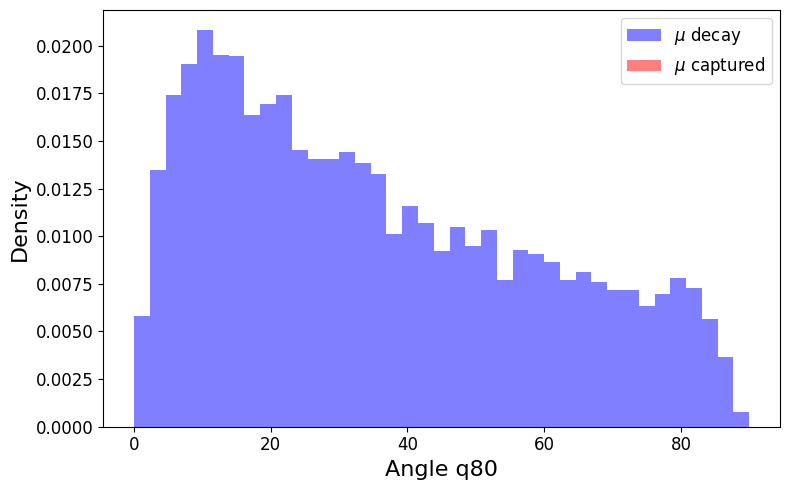

/cvmfs/larsoft.opensciencegrid.org/spack-fnal-v1.0.0/opt/spack/linux-x86_64_v2/py-numpy-1.26.4-bjfwdigla2ihyygih63foelrl4jedvx2/lib/python3.10/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


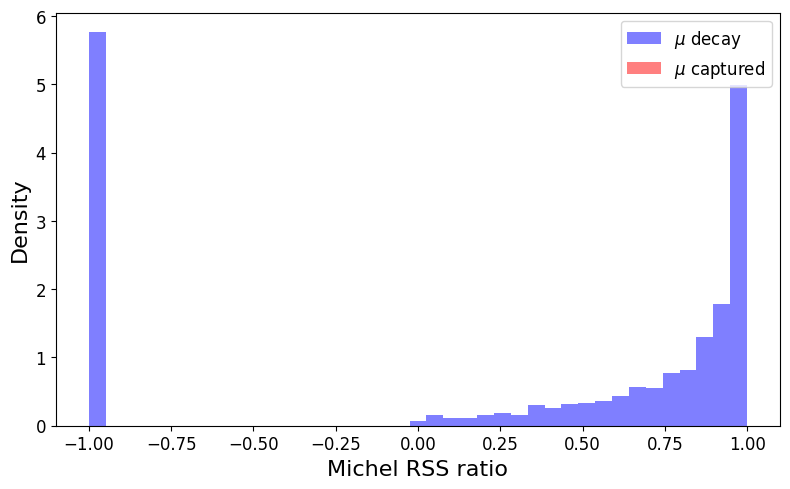

/cvmfs/larsoft.opensciencegrid.org/spack-fnal-v1.0.0/opt/spack/linux-x86_64_v2/py-numpy-1.26.4-bjfwdigla2ihyygih63foelrl4jedvx2/lib/python3.10/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


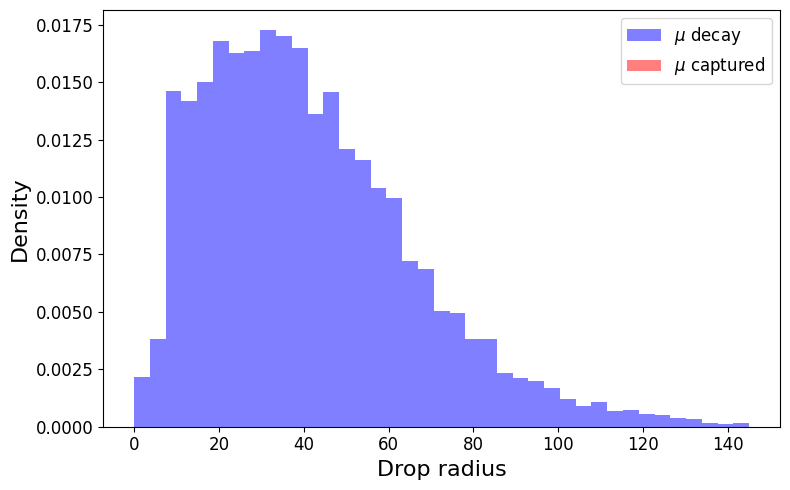

/cvmfs/larsoft.opensciencegrid.org/spack-fnal-v1.0.0/opt/spack/linux-x86_64_v2/py-numpy-1.26.4-bjfwdigla2ihyygih63foelrl4jedvx2/lib/python3.10/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


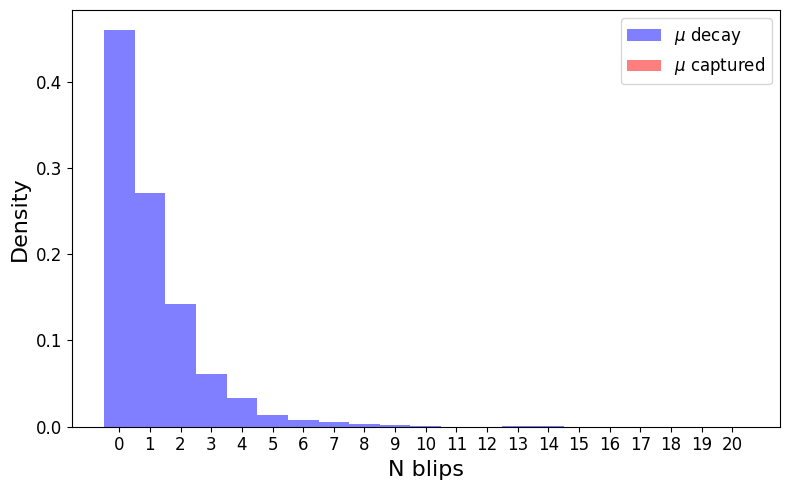

/cvmfs/larsoft.opensciencegrid.org/spack-fnal-v1.0.0/opt/spack/linux-x86_64_v2/py-numpy-1.26.4-bjfwdigla2ihyygih63foelrl4jedvx2/lib/python3.10/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


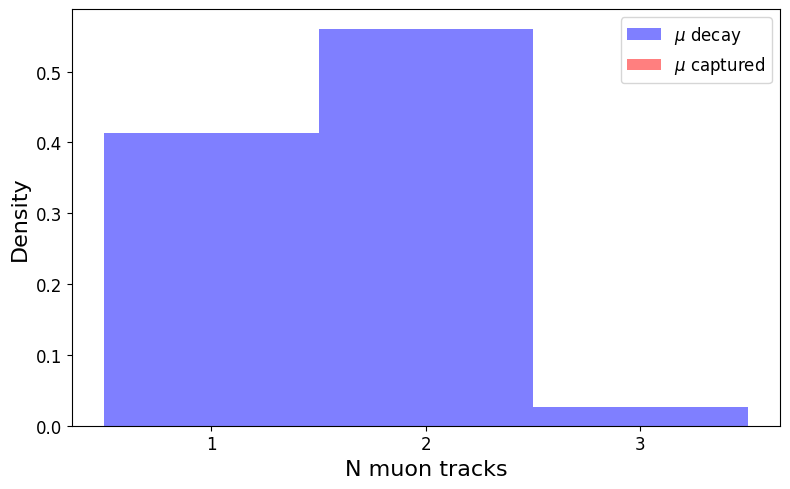

/cvmfs/larsoft.opensciencegrid.org/spack-fnal-v1.0.0/opt/spack/linux-x86_64_v2/py-numpy-1.26.4-bjfwdigla2ihyygih63foelrl4jedvx2/lib/python3.10/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


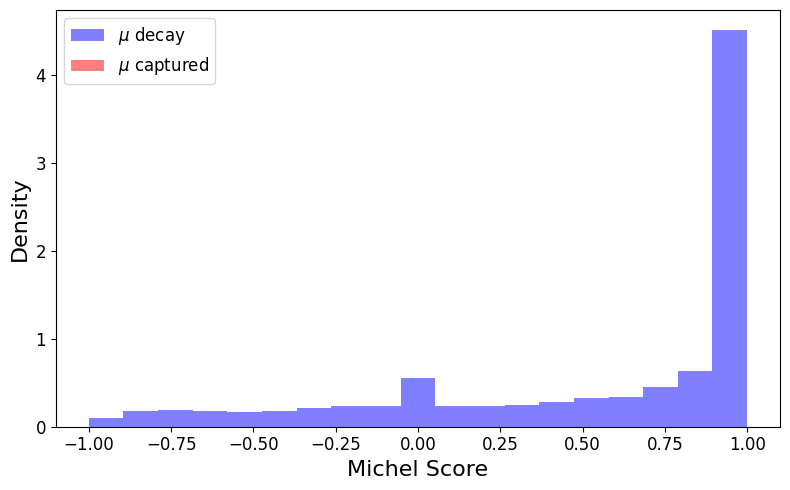

In [17]:
plot_feature(michel_df, 'michel_angle_q80', bins=np.linspace(0,90,40), xlabel='Angle q80')
plot_feature(michel_df, 'michel_rss_ratio', bins=np.linspace(-1, 1, 40), xlabel='Michel RSS ratio')
plot_feature(michel_df, 'michel_drop_radius', bins=np.linspace(0, 145, 40), xlabel='Drop radius')
plot_feature(michel_df, 'michel_n_blips', bins=np.arange(0,21), discrete=True, xlabel='N blips')
plot_feature(michel_df, 'michel_n_muon_tracks', bins=np.arange(1,4), discrete=True, xlabel='N muon tracks')

plot_feature(michel_df, 'michel_score', bins=np.linspace(-1,1,20), xlabel='Michel Score')

In [18]:
michel_df.subrun_id.value_counts()

subrun_id
345     7
2176    6
3075    6
255     6
3152    6
       ..
3990    1
3987    1
1299    1
3979    1
4130    1
Name: count, Length: 3538, dtype: int64

In [19]:
cols = ["file_name", "subrun_id", "run_id", 'slice_id', "event_id", 'prim_lepton_vtx_x', 'prim_lepton_vtx_z', 'true_gap'] + michel_branches

#michel_df[michel_df.michel_vars_computed & (michel_df.subrun_id == 194)][cols]
michel_df[michel_df.michel_vars_computed & (michel_df.subrun_id == 345)][cols]

,file_name,subrun_id,run_id,slice_id,event_id,prim_lepton_vtx_x,prim_lepton_vtx_z,true_gap,michel_vars_computed,michel_n_muon_tracks,michel_rss_ratio,michel_angle_q80,michel_drop_radius,michel_n_blips,michel_score
37218,,345,1,0,15,178.779877,390.428467,3.277630,True,2,-1.000000,9.121041,18.436645,1,0.540635
37219,,345,1,0,19,-72.411568,189.711746,19.355697,True,1,-1.000000,5.134855,9.683536,0,-0.698711
37220,,345,1,0,27,69.671860,285.712097,2.590396,True,2,-1.000000,40.595485,14.456983,4,0.287529
37222,,345,1,0,42,-142.947174,257.561188,1.956346,True,1,0.998987,12.560728,32.711672,0,0.431902
37226,,345,1,2,50,49.468548,29.101765,3.780384,True,2,0.735894,38.029214,13.007073,0,0.975835
37228,,345,1,0,56,80.570053,323.535370,1.149284,True,2,0.068730,11.353655,21.218533,2,0.886503
37234,,345,1,0,72,-51.805473,332.137604,3.168154,True,2,-1.000000,69.459447,124.343545,1,0.830248


In [20]:
ana_idx = {
        b: ana_tree[b].array(library="np", entry_stop=None)
        for b in ['file_name','event_id','run_id','subrun_id', 'slc_id']
    }

In [21]:
ana_df = pd.DataFrame(ana_idx)

In [22]:
mask = (ana_df.subrun_id == 345) #& (ana_df.run_id == 1) & (ana_df.event_id == )

ana_df.loc[mask, ['file_name','event_id','run_id','subrun_id', 'slc_id']]

,file_name,event_id,run_id,subrun_id,slc_id
37217,reco2_2721.root,1,1,345,0
37218,reco2_2721.root,2,1,345,4294967295
37219,reco2_2721.root,11,1,345,4294967295
37220,reco2_2721.root,13,1,345,4294967295
37221,reco2_2721.root,14,1,345,0
37222,reco2_2721.root,15,1,345,0
37223,reco2_2721.root,19,1,345,0
37224,reco2_2721.root,27,1,345,0
37225,reco2_2721.root,29,1,345,4294967295
37226,reco2_2721.root,42,1,345,0


# Michel true props

In [23]:
data.keys()

dict_keys(['file_name', 'event_id', 'run_id', 'subrun_id', 'slice_id', 'gen_index', 'nu_pdg', 'nu_e0', 'nu_weight', 'nu_int_mode', 'nu_int_type', 'nu_cc_nc', 'nu_target', 'nu_hit_nuc', 'nu_hit_quark', 'nu_w', 'nu_x', 'nu_y', 'nu_q_sqr', 'n_protons', 'n_neutrons', 'n_pi0', 'n_pip', 'n_pim', 'n_mup', 'n_mum', 'n_ep', 'n_em', 'n_lambda', 'n_sigma0', 'n_sigmap', 'n_sigmam', 'n_hyperon', 'true_gap', 'is_lambda_signal', 'has_lambda', 'has_lambda_v', 'prim_lepton_vtx_x', 'prim_lepton_vtx_y', 'prim_lepton_vtx_z', 'frans_score', 'true_muon_in_fv', 'true_muon_decay', 'michel_vars_computed', 'michel_n_muon_tracks', 'michel_rss_ratio', 'michel_angle_q80', 'michel_drop_radius', 'michel_n_blips', 'michel_score', 'frans_succeed'])

In [24]:
true_michel_mask = data["is_lambda_signal"] & data["true_muon_in_fv"] & data["true_muon_decay"]

In [25]:
mu_mask = abs(data["g4_pdg"]) == 13

KeyError: 'g4_pdg'

# Michel reco

In [ ]:
reco_branches = ['file_name',
 'event_id',
 'run_id',
 'subrun_id',
 'event_n_slices',
 'slc_filled',
 'slc_id',
 'slc_vtx_x',
 'slc_vtx_y',
 'slc_vtx_z',
 'slc_vtx_wire_u',
 'slc_vtx_wire_v',
 'slc_vtx_wire_c',
 'slc_vtx_channel_u',
 'slc_vtx_channel_v',
 'slc_vtx_channel_c',
 'slc_vtx_time_tick',
 'slc_n_pfp',
 'slc_prim_id',
 'slc_prim_pdg',
 'slc_is_clear_cosmic',
 'slc_nu_score',
 'slc_bcfm_time',
 'slc_bcfm_radius',
 'slc_bcfm_chi2',
 'slc_bcfm_score',
 'slc_bcfm_pe',
 'slc_true_vtx_x',
 'slc_true_vtx_y',
 'slc_true_vtx_z',
 'slc_true_vtx_wire_u',
 'slc_true_vtx_wire_v',
 'slc_true_vtx_wire_c',
 'slc_true_vtx_channel_u',
 'slc_true_vtx_channel_v',
 'slc_true_vtx_channel_c',
 'slc_true_vtx_time_tick',
 'slc_truthmatch_comp',
 'slc_truthmatch_pur',
 'slc_pfp_id',
 'slc_pfp_mother',
 'slc_pfp_is_primary',
 'slc_pfp_pandora_pdg',
 'slc_pfp_track_score',
 'slc_pfp_vtx_x',
 'slc_pfp_vtx_y',
 'slc_pfp_vtx_z',
 'slc_pfp_vtx_wire_u',
 'slc_pfp_vtx_wire_v',
 'slc_pfp_vtx_wire_c',
 'slc_pfp_vtx_channel_u',
 'slc_pfp_vtx_channel_v',
 'slc_pfp_vtx_channel_c',
 'slc_pfp_n_hits_u',
 'slc_pfp_n_hits_v',
 'slc_pfp_n_hits_c',
 'slc_pfp_track_length',
 'slc_pfp_track_theta',
 'slc_pfp_track_phi',
 'slc_pfp_track_start_x',
 'slc_pfp_track_start_y',
 'slc_pfp_track_start_z',
 'slc_pfp_track_start_wire_u',
 'slc_pfp_track_start_wire_v',
 'slc_pfp_track_start_wire_c',
 'slc_pfp_track_start_channel_u',
 'slc_pfp_track_start_channel_v',
 'slc_pfp_track_start_channel_c',
 'slc_pfp_track_start_time_tick',
 'slc_pfp_track_end_x',
 'slc_pfp_track_end_y',
 'slc_pfp_track_end_z',
 'slc_pfp_track_end_wire_u',
 'slc_pfp_track_end_wire_v',
 'slc_pfp_track_end_wire_c',
 'slc_pfp_track_end_channel_u',
 'slc_pfp_track_end_channel_v',
 'slc_pfp_track_end_channel_c',
 'slc_pfp_track_end_time_tick',
 'slc_pfp_track_dir_x',
 'slc_pfp_track_dir_y',
 'slc_pfp_track_dir_z',]

In [ ]:
reco_data = {
        b: ana_tree[b].array(library="ak", entry_stop=None)
        for b in reco_branches
    }

In [ ]:
idx_mask = (reco_data['subrun_id'] == 345) & (reco_data['event_id'] == 42)

In [ ]:
sum(idx_mask)

In [ ]:
reco_data['slc_pfp_id'][idx_mask]

In [ ]:
cols = ['slc_pfp_id', 'slc_pfp_track_start_z', 'slc_pfp_track_end_z', 'slc_pfp_track_start_x', 'slc_pfp_track_end_x']

for c in cols:
    print(f'{c}: {reco_data[c][idx_mask]}')

# Small new sample

In [ ]:
fransDir2 = Path("/exp/sbnd/data/users/syebes/LambdaAnalysis/michelTagging")
lambdaFile2 = "fransOutput_R1-1_SR345-345.root.root"
fransTDir2 = "FRANSProducer/fransTree"

In [ ]:
file2 = uproot.open(fransDir / lambdaFile)

fransTree2 = file[fransTDir]

In [ ]:
data2 = {
        b: fransTree2[b].array(library="np", entry_stop=None)
        for b in branches
    }

In [ ]:
df2 = pd.DataFrame(data2)

In [ ]:
true_michel_mask2 = (df2.is_lambda_signal) & (df2.true_muon_in_fv) & (df2.true_muon_decay)

michel_df2 = df2[true_michel_mask2]

In [ ]:
cols = ["file_name", "subrun_id", "run_id", 'slice_id', "event_id", 'prim_lepton_vtx_x', 'prim_lepton_vtx_z'] + michel_branches

michel_df2[michel_df2.michel_vars_computed & (michel_df2.subrun_id == 345)][cols]

# New bdt

In [28]:
from xgboost import XGBClassifier

bdt = XGBClassifier()
bdt.load_model("xgb_model_blips_range.json")

In [32]:
features = [
    'n_mu_tracks',
    'lower_chi2_ratio',
    'angle_q80',
    'drop_radius',
    'n_blips',
]


michel_df['n_mu_tracks'] = michel_df['michel_n_muon_tracks']
michel_df['lower_chi2_ratio'] = michel_df['michel_rss_ratio']
michel_df['angle_q80'] = michel_df['michel_angle_q80']
michel_df['drop_radius'] = michel_df['michel_drop_radius']
michel_df['n_blips'] = michel_df['michel_n_blips']




X = michel_df[features]

proba = bdt.predict_proba(X)

/tmp/ipykernel_15742/1077293470.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  michel_df['n_mu_tracks'] = michel_df['michel_n_muon_tracks']
/tmp/ipykernel_15742/1077293470.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  michel_df['lower_chi2_ratio'] = michel_df['michel_rss_ratio']
/tmp/ipykernel_15742/1077293470.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the document

In [35]:
proba[:,0]

array([0.24445033, 0.18907928, 0.5810391 , ..., 0.05332792, 0.14410543,
       0.05450779], dtype=float32)

In [36]:
michel_df['local_score'] = proba[:,0]

/tmp/ipykernel_15742/33317088.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  michel_df['local_score'] = proba[:,0]


/cvmfs/larsoft.opensciencegrid.org/spack-fnal-v1.0.0/opt/spack/linux-x86_64_v2/py-numpy-1.26.4-bjfwdigla2ihyygih63foelrl4jedvx2/lib/python3.10/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


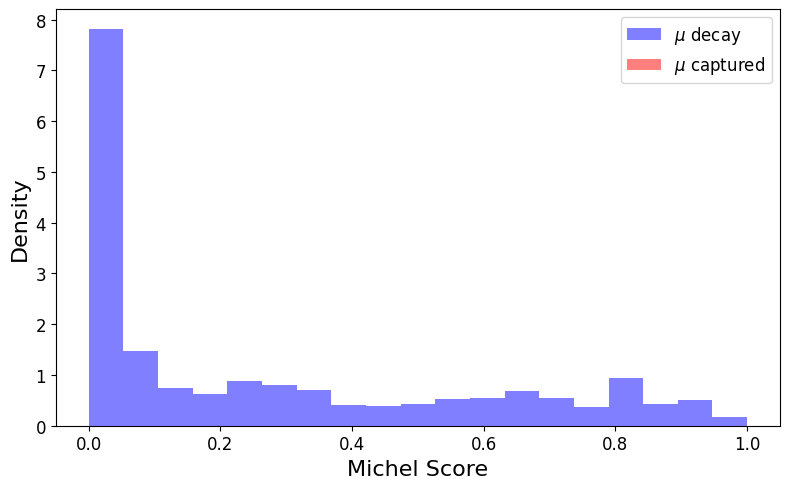

In [38]:
plot_feature(michel_df, 'local_score', bins=np.linspace(0,1,20), xlabel='Michel Score')

In [27]:
print(os.getcwd())

/home/syebes/lambda-selection/notebooks
